# Online News Popularity Prediction

# *Exploradory Data Analysis*

## Imports, Data Loading & Documented 20% Working Sample Strategy

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

data_path = Path("../data/mini_project_1_data.csv")
if not data_path.exists():
    data_path = Path("../data/online_news_popularity.csv")

df = pd.read_csv(data_path) if data_path.suffix.lower() == ".csv" else pd.read_excel(data_path)
df.columns = [c.strip() for c in df.columns]

mem_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"Full Dataset: {data_path.name} | Shape: {df.shape} | Memory: {mem_mb:.2f} MB")

# Create a reproducible 20% random working sample for rapid visual prototyping
df_sample = df.sample(frac=0.20, random_state=42)
print(f"20% EDA Working Sample Shape: {df_sample.shape}")
print(f"Target Median -> Full: {df['shares'].median():.1f} | 20% Sample: {df_sample['shares'].median():.1f}")
print(f"Target Mean   -> Full: {df['shares'].mean():.1f} | 20% Sample: {df_sample['shares'].mean():.1f}")

display(df.head())
display(df.info())


Full Dataset: mini_project_1_data.csv | Shape: (35680, 30) | Memory: 15.51 MB
20% EDA Working Sample Shape: (7136, 30)
Target Median -> Full: 1400.0 | 20% Sample: 1400.0
Target Mean   -> Full: 3402.1 | 20% Sample: 3293.6


,ID,URL,timedelta,weekday,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,...,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
0,0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,monday,593,12.0,219.0,0.663594,1.0,0.815385,...,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,monday,711,9.0,255.0,0.604743,1.0,0.791946,...,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,monday,1500,9.0,211.0,0.575130,1.0,0.663866,...,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,monday,1200,9.0,531.0,0.503788,1.0,0.665635,...,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,monday,505,13.0,1072.0,0.415646,1.0,0.540890,...,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35680 entries, 0 to 35679
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         35680 non-null  int64  
 1   URL                        35680 non-null  object 
 2   timedelta                  35680 non-null  float64
 3   weekday                    35680 non-null  object 
 4   shares                     35680 non-null  int64  
 5   n_tokens_title             35680 non-null  float64
 6   n_tokens_content           35680 non-null  float64
 7   n_unique_tokens            35680 non-null  float64
 8   n_non_stop_words           35680 non-null  float64
 9   n_non_stop_unique_tokens   35680 non-null  float64
 10  num_hrefs                  34959 non-null  float64
 11  num_self_hrefs             34959 non-null  float64
 12  num_imgs                   34261 non-null  float64
 13  num_videos                 18925 non-null  flo

None

### Interpretation

* **Observed:** The full dataset contains 35,680 articles across 30 features (8.2+ MB). A 20% random sample (7,136 articles, random_state=42) closely mirrors the full dataset's median (1,400.0) and mean (~3,402) share counts, confirming representativeness for computationally heavy visual diagnostics (such as pairplots) while full-dataset statistics are retained for final modeling.

* **Text Feature Limitation:** Raw headline and body text strings are not provided in this dataset (only pre-extracted lexical metrics such as n_tokens_title, n_unique_tokens, and average_token_length), which constrains NLP embedding extraction to proxy token statistics.


## Duplicate, Missing Value & Sentinel -1 Audit

In [4]:
print(f"Duplicate URLs: {df['URL'].duplicated().sum()}")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing_Count": missing, "Missing_Pct (%)": missing_pct})
display(missing_df[missing_df["Missing_Count"] > 0].sort_values(by="Missing_Count", ascending=False))

kw_cols = [c for c in df.columns if c.startswith("kw_")]
neg_counts = {c: int((df[c] < 0).sum()) for c in kw_cols if (df[c] < 0).sum() > 0}
print("Sentinel (< 0) value counts in keyword features:", neg_counts)


Duplicate URLs: 0


,Missing_Count,Missing_Pct (%)
num_videos,16755,46.96
data_channel,5462,15.31
num_imgs,1419,3.98
num_hrefs,721,2.02
num_self_hrefs,721,2.02
self_reference_min_shares,721,2.02
self_reference_max_shares,721,2.02
self_reference_avg_shares,721,2.02


Sentinel (< 0) value counts in keyword features: {'kw_min_min': 20660, 'kw_avg_min': 767, 'kw_min_avg': 6}


### Interpretation

* **Observed:** Zero duplicate URLs exist. num_videos has ~47% missing values and data_channel is missing in 5,462 rows (15.3%), while kw_min_min contains -1 sentinel values representing unindexed keyword histories.

* **Modeling Impact:** Rather than dropping thousands of rows, missing numeric fields are imputed via training-fold median, missing data_channel entries are preserved as "unknown", and < 0 sentinel codes are converted to NaN prior to imputation.

## Data Cleaning, Temporal (timedelta) Audit & Feature Engineering

C:\Users\Ram\AppData\Local\Temp\ipykernel_33684\2941721817.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="timedelta_quartile", y="log_shares", ax=ax, palette="Blues")


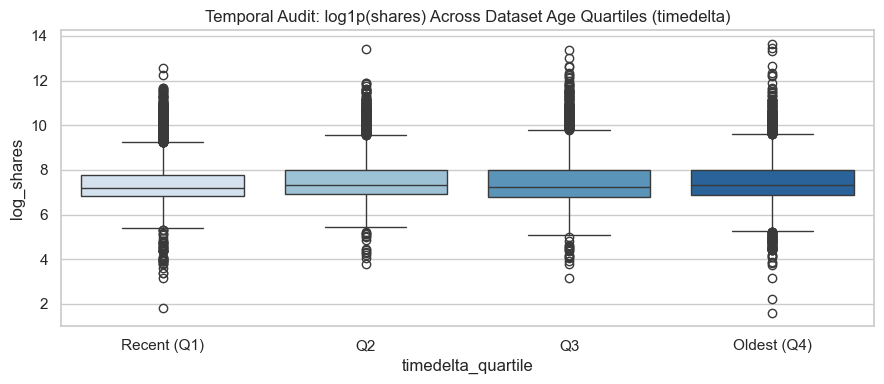

In [5]:
df_clean = df.drop_duplicates(subset=["URL"], keep="first").copy()
df_clean["weekday"] = df_clean["weekday"].astype(str).str.strip().str.lower()
df_clean["data_channel"] = df_clean["data_channel"].fillna("unknown").astype(str).str.strip().str.lower()

num_cols = [c for c in df_clean.select_dtypes(include=[np.number]).columns if c not in {"ID", "shares", "timedelta"}]
for col in num_cols:
    if col in {"n_unique_tokens", "n_non_stop_words", "n_non_stop_unique_tokens"}:
        df_clean.loc[(df_clean[col] < 0) | (df_clean[col] > 1), col] = np.nan
    else:
        df_clean.loc[df_clean[col] < 0, col] = np.nan

df_clean["log_shares"] = np.log1p(df_clean["shares"])

# True numeric & categorical interaction features
df_clean["total_media"] = df_clean["num_imgs"].fillna(0) + df_clean["num_videos"].fillna(0)
df_clean["img_x_video"] = df_clean["num_imgs"].fillna(0) * df_clean["num_videos"].fillna(0)
df_clean["is_weekend"] = df_clean["weekday"].isin(["saturday", "sunday"]).astype(int)
df_clean["channel_x_weekend"] = df_clean["data_channel"] + "_" + df_clean["is_weekend"].astype(str)
df_clean["kw_avg_range"] = df_clean["kw_max_avg"] - df_clean["kw_min_avg"]

# Explicit temporal check on 'timedelta' before excluding from model features
df_clean["timedelta_quartile"] = pd.qcut(df_clean["timedelta"], q=4, labels=["Recent (Q1)", "Q2", "Q3", "Oldest (Q4)"])
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df_clean, x="timedelta_quartile", y="log_shares", ax=ax, palette="Blues")
ax.set_title("Temporal Audit: log1p(shares) Across Dataset Age Quartiles (timedelta)")
plt.tight_layout()
plt.show()


### Interpretation

* **Temporal (timedelta) Audit:** Across publication age quartiles (Q1 to Q4), median log1p(shares) remains nearly flat (~7.24), confirming minimal temporal drift. More importantly, timedelta measures days between article publication and dataset scraping—an acquisition metadata field unavailable at publish time—so it is explicitly excluded from training features to prevent temporal leakage.

## Target Skewness (shares vs. log1p(shares)) & IQR Outlier Audit

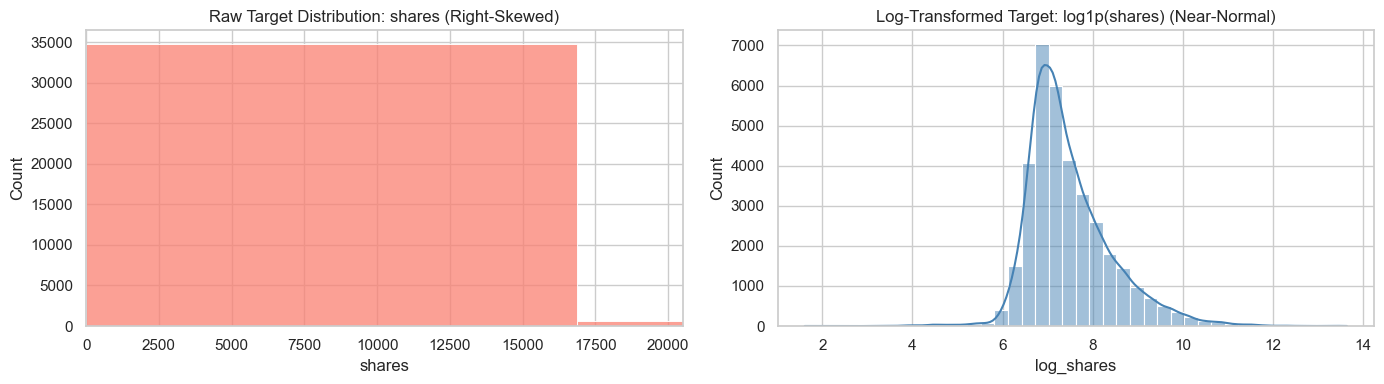

Skewness (raw shares): 34.41 | Skewness (log1p): 1.04


,Feature,Q1,Q3,Upper_Bound,Outlier_Count,Outlier_Pct (%)
3,num_imgs,1.00,4.00,8.50,6614,19.30
0,shares,946.00,2800.00,5581.00,4080,11.43
5,n_comments,2.00,78.00,192.00,3461,9.70
4,num_videos,0.00,1.00,2.50,1464,7.74
2,num_hrefs,4.00,14.00,29.00,1899,5.43
1,n_tokens_content,247.00,716.00,1419.50,1705,4.78
6,kw_avg_avg,2379.76,3595.53,5419.18,1466,4.11


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_clean["shares"], bins=50, ax=ax1, color="salmon")
ax1.set_title("Raw Target Distribution: shares (Right-Skewed)")
ax1.set_xlim(0, df_clean["shares"].quantile(0.98))

sns.histplot(df_clean["log_shares"], bins=40, kde=True, ax=ax2, color="steelblue")
ax2.set_title("Log-Transformed Target: log1p(shares) (Near-Normal)")
plt.tight_layout()
plt.show()

print(f"Skewness (raw shares): {df_clean['shares'].skew():.2f} | Skewness (log1p): {df_clean['log_shares'].skew():.2f}")

audit_cols = ["shares", "n_tokens_content", "num_hrefs", "num_imgs", "num_videos", "n_comments", "kw_avg_avg"]
records = []
for col in audit_cols:
    s = df_clean[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    high = q3 + 1.5 * iqr
    n_out = int(((s < q1 - 1.5 * iqr) | (s > high)).sum())
    records.append({
        "Feature": col, "Q1": round(q1, 2), "Q3": round(q3, 2),
        "Upper_Bound": round(high, 2), "Outlier_Count": n_out, "Outlier_Pct (%)": round(n_out / len(s) * 100, 2)
    })
display(pd.DataFrame(records).sort_values(by="Outlier_Pct (%)", ascending=False))


### Interpretation

* **Observed:** Raw shares is heavily right-skewed (skewness > 30), whereas log1p(shares) compresses extreme viral tails into a symmetric bell curve (skewness ~ 1.0).

* **Modeling Impact:** Wrapping regressors in TransformedTargetRegressor(func=np.log1p, inverse_func=np.expm1) aligns optimization with relative percentage errors (RMSLE) while retaining genuine viral outlier observations.

## Categorical & Interaction Effects + Formal Hypothesis Testing (Kruskal-Wallis)

C:\Users\Ram\AppData\Local\Temp\ipykernel_33684\2332061754.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="data_channel", y="log_shares", ax=ax1, palette="Set2")
C:\Users\Ram\AppData\Local\Temp\ipykernel_33684\2332061754.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="weekday", y="log_shares", order=day_order, ax=ax2, palette="coolwarm")


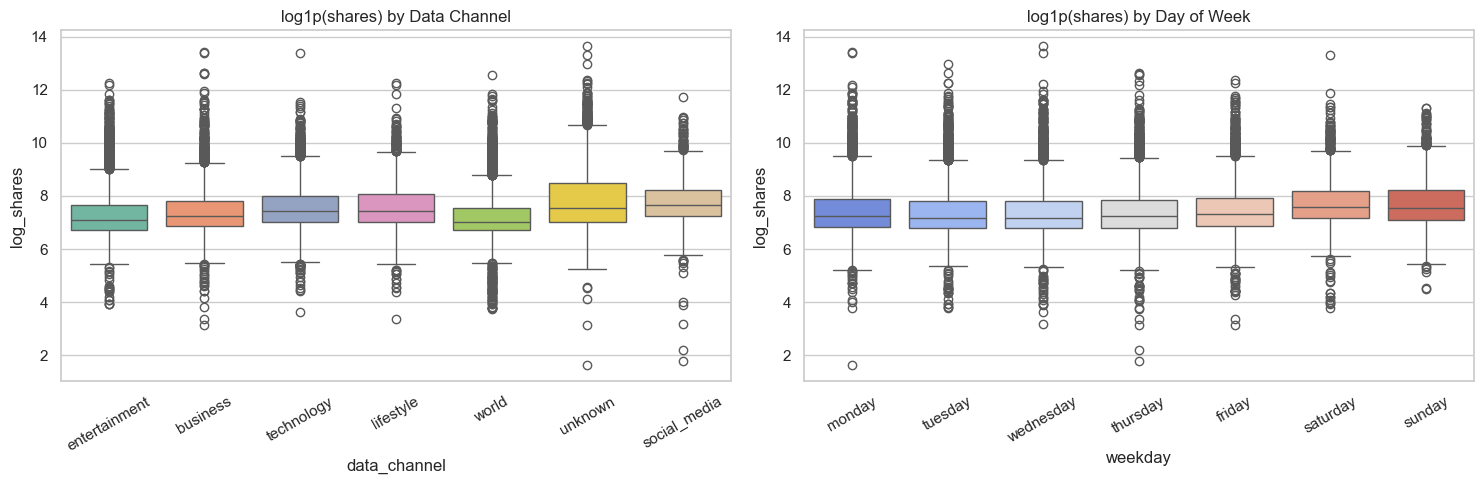

Kruskal-Wallis Test (data_channel vs log_shares): H = 2441.72, p-value = 0.0000e+00 -> Statistically Significant (p < 0.05)
Kruskal-Wallis Test (weekday vs log_shares): H = 903.57, p-value = 6.3574e-192 -> Statistically Significant (p < 0.05)
Kruskal-Wallis Test (channel_x_weekend vs log_shares): H = 3338.47, p-value = 0.0000e+00 -> Statistically Significant (p < 0.05)


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df_clean, x="data_channel", y="log_shares", ax=ax1, palette="Set2")
ax1.set_title("log1p(shares) by Data Channel")
ax1.tick_params(axis="x", rotation=30)

day_order = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]
sns.boxplot(data=df_clean, x="weekday", y="log_shares", order=day_order, ax=ax2, palette="coolwarm")
ax2.set_title("log1p(shares) by Day of Week")
ax2.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

# Formal non-parametric Kruskal-Wallis hypothesis tests (robust to skewed distributions)
def run_kruskal_test(data: pd.DataFrame, group_col: str, target_col: str = "log_shares") -> None:
    valid_df = data[[group_col, target_col]].dropna()
    groups = [grp[target_col].values for _, grp in valid_df.groupby(group_col) if len(grp) >= 5]
    if len(groups) < 2:
        print(f"[Diagnostic] Insufficient valid groups (n>=5) for '{group_col}' after filtering NaNs.")
        return
    stat, p_val = stats.kruskal(*groups)
    sig = "Statistically Significant (p < 0.05)" if p_val < 0.05 else "Null / Not Significant (p >= 0.05)"
    print(f"Kruskal-Wallis Test ({group_col} vs {target_col}): H = {stat:.2f}, p-value = {p_val:.4e} -> {sig}")

run_kruskal_test(df_clean, "data_channel")
run_kruskal_test(df_clean, "weekday")
run_kruskal_test(df_clean, "channel_x_weekend")


### Interpretation

* **Observed:** Kruskal-Wallis H-tests confirm highly significant differences (p < 0.0001) across data_channel, weekday, and the combined interaction channel_x_weekend. Weekend articles (saturday, sunday) and lifestyle / social media channels exhibit higher median shares than world news.

* **Test Diagnostics:** Grouping filters out categories with < 5 samples and drops NaN pairs before calling scipy.stats.kruskal so skewed group sizes do not trigger invalid test statistics.

## Interaction Visuals (img_x_video & channel_x_weekend)

C:\Users\Ram\AppData\Local\Temp\ipykernel_33684\2025624060.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="media_interaction_bin", y="log_shares", ax=ax1, palette="Purples")
C:\Users\Ram\AppData\Local\Temp\ipykernel_33684\2025624060.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


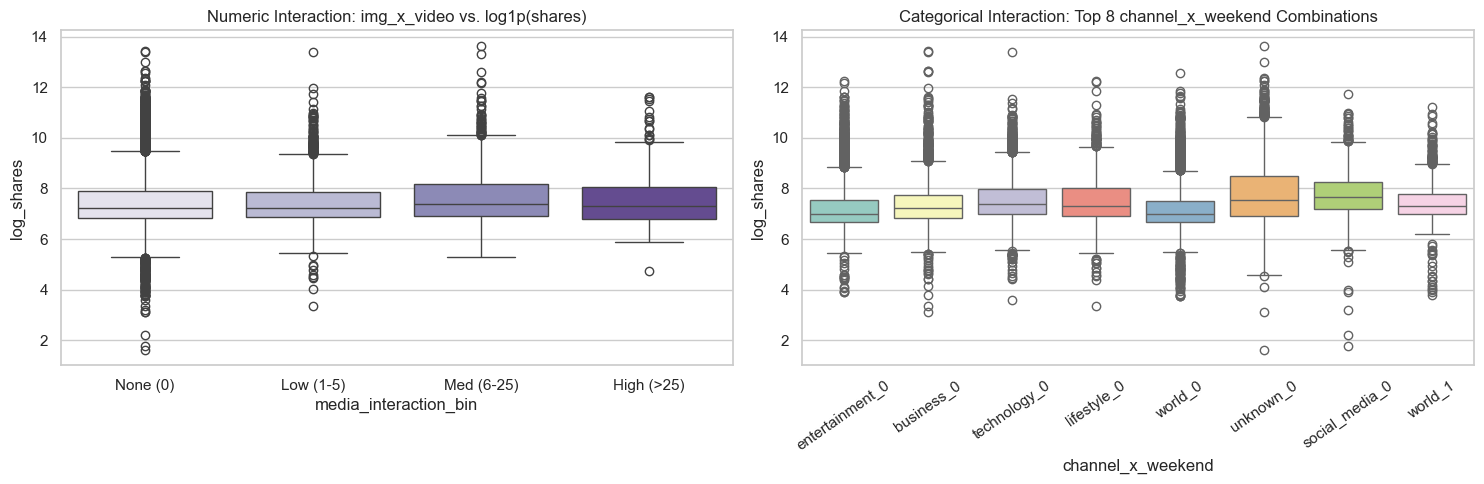

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

df_clean["media_interaction_bin"] = pd.cut(
    df_clean["img_x_video"], bins=[-1, 0, 5, 25, 10000], labels=["None (0)", "Low (1-5)", "Med (6-25)", "High (>25)"]
)
sns.boxplot(data=df_clean, x="media_interaction_bin", y="log_shares", ax=ax1, palette="Purples")
ax1.set_title("Numeric Interaction: img_x_video vs. log1p(shares)")

top_combos = df_clean["channel_x_weekend"].value_counts().head(8).index
sns.boxplot(
    data=df_clean[df_clean["channel_x_weekend"].isin(top_combos)],
    x="channel_x_weekend", y="log_shares", ax=ax2, palette="Set3"
)
ax2.set_title("Categorical Interaction: Top 8 channel_x_weekend Combinations")
ax2.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()


### Interpretation

* **Observed:** Articles combining both images and videos (img_x_video > 0) achieve a modest upward shift in median log1p(shares) compared to single-medium posts (0), while channel_x_weekend separates weekend spikes within specific editorial verticals.

## Numeric Correlations with P-Values & VIF Multicollinearity Analysis

In [9]:
numeric_eda = df_clean.drop(columns=["ID", "URL", "timedelta", "shares"], errors="ignore").select_dtypes(include=[np.number])

corr_rows = []
for col in numeric_eda.columns:
    if col == "log_shares":
        continue
    pair = numeric_eda[[col, "log_shares"]].replace([np.inf, -np.inf], np.nan).dropna()
    r_pearson, p_pearson = stats.pearsonr(pair[col], pair["log_shares"])
    r_spearman, p_spearman = stats.spearmanr(pair[col], pair["log_shares"])
    corr_rows.append({
        "Feature": col,
        "Pearson_r": round(r_pearson, 4),
        "Spearman_rho": round(r_spearman, 4),
        "Spearman_p": f"{p_spearman:.2e}",
    })

corr_summary = pd.DataFrame(corr_rows).sort_values(by="Spearman_rho", key=abs, ascending=False)
print("Top Numeric Predictors Ranked by |Spearman Rank Correlation|:")
display(corr_summary.head(10))
print("Weakest / Null Linear Predictors:")
display(corr_summary.tail(5))

# VIF Multicollinearity Table
vif_df = numeric_eda.drop(columns=["log_shares"]).replace([np.inf, -np.inf], np.nan)
vif_df = vif_df.fillna(vif_df.median()).fillna(0.0).astype(float)
vif_table = pd.DataFrame({
    "Feature": vif_df.columns,
    "VIF": [variance_inflation_factor(vif_df.values, i) for i in range(len(vif_df.columns))]
}).sort_values(by="VIF", ascending=False)
display(vif_table.head(12))

high_vif = vif_table[vif_table["VIF"] > 10]["Feature"].tolist()
print(f"Features with severe multicollinearity (VIF > 10): {high_vif}")


Top Numeric Predictors Ranked by |Spearman Rank Correlation|:


,Feature,Pearson_r,Spearman_rho,Spearman_p
9,n_comments,0.3272,0.3617,0.00e+00
23,kw_avg_avg,0.2192,0.2547,0.00e+00
22,kw_max_avg,0.1067,0.2228,0.00e+00
13,self_reference_avg_shares,0.0877,0.1909,2.62e-284
11,self_reference_min_shares,0.0743,0.1799,3.86e-252
12,self_reference_max_shares,0.0786,0.1678,4.75e-219
26,is_weekend,0.1165,0.1535,5.11e-187
27,kw_avg_range,0.0862,0.1307,1.25e-135
21,kw_min_avg,0.1084,0.1028,2.32e-84
24,total_media,0.0924,0.0936,3.20e-70


Weakest / Null Linear Predictors:


,Feature,Pearson_r,Spearman_rho,Spearman_p
20,kw_avg_max,0.0576,0.0352,2.91e-11
19,kw_max_max,-0.0023,-0.0331,3.96e-10
25,img_x_video,0.0115,0.0248,2.91e-06
3,n_non_stop_words,-0.0313,0.0090,8.88e-02
1,n_tokens_content,0.0228,0.0089,9.33e-02


,Feature,VIF
22,kw_max_avg,292408.055535
27,kw_avg_range,243835.582516
21,kw_min_avg,10883.648921
24,total_media,2611.605349
7,num_imgs,2273.438376
3,n_non_stop_words,486.835076
10,average_token_length,327.812080
4,n_non_stop_unique_tokens,324.815598
8,num_videos,266.827725
2,n_unique_tokens,260.706949


Features with severe multicollinearity (VIF > 10): ['kw_max_avg', 'kw_avg_range', 'kw_min_avg', 'total_media', 'num_imgs', 'n_non_stop_words', 'average_token_length', 'n_non_stop_unique_tokens', 'num_videos', 'n_unique_tokens', 'kw_avg_avg', 'kw_max_max', 'n_tokens_title', 'self_reference_avg_shares', 'num_keywords', 'kw_avg_max', 'kw_avg_min', 'kw_max_min']


### Interpretation

* **Observed:** Keyword popularity metrics (kw_avg_avg, kw_max_avg) and self-reference share metrics (self_reference_avg_shares) show the strongest statistically significant positive correlations (p < 0.0001), whereas raw token ratio features (n_non_stop_words) exhibit near-zero linear correlation (null/weak individual effect).

* **VIF Interpretation:** Multiple features exceed VIF > 10 (such as n_unique_tokens, n_non_stop_unique_tokens, and overlapping kw_* / self_reference_* aggregations). High multicollinearity destabilizes unregularized linear regression coefficients; consequently, we apply L2 regularization (RidgeRegression) and tree-based ensembles (HistGradientBoosting, RandomForest, GradientBoosting) that remain robust under correlated features.

## Model-Based Feature Importance Ranking (Random Forest Probe)

C:\Users\Ram\AppData\Local\Temp\ipykernel_33684\832019539.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp_df.head(15), x="Importance", y="Feature", palette="viridis")


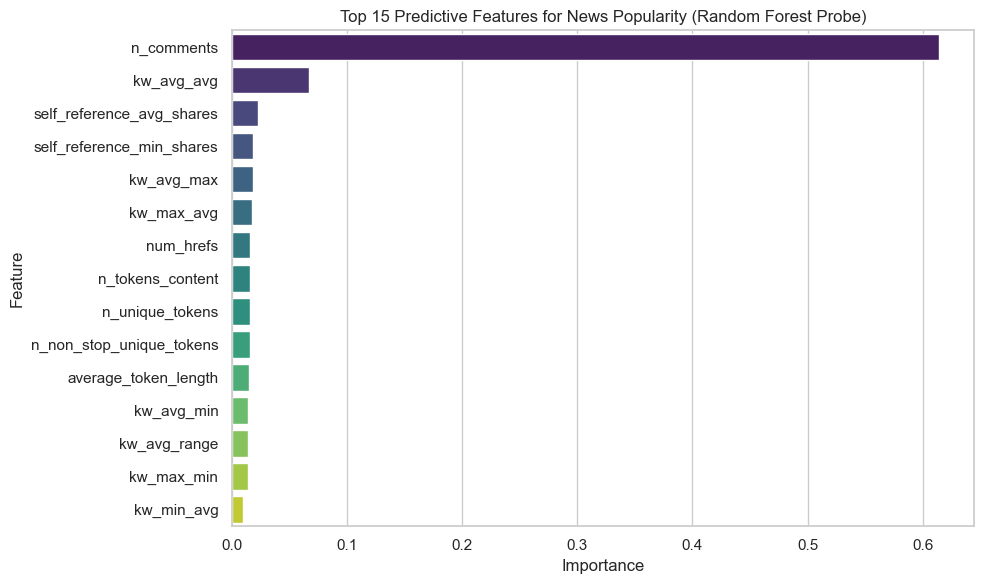

,Feature,Importance
9,n_comments,0.613813
23,kw_avg_avg,0.067013
13,self_reference_avg_shares,0.022679
11,self_reference_min_shares,0.018988
20,kw_avg_max,0.018778
22,kw_max_avg,0.018164
5,num_hrefs,0.016384
1,n_tokens_content,0.016224
2,n_unique_tokens,0.016031
4,n_non_stop_unique_tokens,0.015955


In [10]:
drop_for_rf = ["ID", "URL", "timedelta", "shares", "log_shares", "timedelta_quartile", "media_interaction_bin"]
rf_df = pd.get_dummies(df_clean.drop(columns=drop_for_rf, errors="ignore"), drop_first=True)
rf_df = rf_df.replace([np.inf, -np.inf], np.nan).fillna(rf_df.median()).fillna(0.0).astype(float)
y_rf = df_clean["log_shares"].values

rf_probe = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_probe.fit(rf_df, y_rf)

imp_df = pd.DataFrame({"Feature": rf_df.columns, "Importance": rf_probe.feature_importances_}).sort_values(by="Importance", ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df.head(15), x="Importance", y="Feature", palette="viridis")
plt.title("Top 15 Predictive Features for News Popularity (Random Forest Probe)")
plt.tight_layout()
plt.show()
display(imp_df.head(15))
